# Face Recognition on a Dataset (Olivetti Faces)

Identify **who** is in a photo, using a small, fast-to-run dataset:

- **Dataset:** Olivetti faces, 400 grayscale images (64x64) of 40 people, 10 photos each (a few MB, downloaded automatically by scikit-learn)
- **Method 1:** Eigenfaces (PCA) + SVM, a classic and very fast baseline
- **Method 2:** A small CNN with TensorFlow/Keras

Both finish in about a minute or two on a normal CPU.

## 1. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.22.0-rc0


## 2. Load the dataset

In [2]:
try:
    faces = fetch_olivetti_faces(shuffle=True, random_state=SEED)
except Exception as e:
    raise RuntimeError(
        "Could not download the Olivetti dataset. Check your internet connection and re-run this cell. "
        "(It is fetched once and cached on disk afterwards.)") from e

X = faces.images.astype("float32")      # (400, 64, 64), values in [0, 1]
y = faces.target                        # person id 0..39
n_people = len(np.unique(y))
print("Images:", X.shape, "| People:", n_people, "| Images per person:", np.bincount(y)[0])

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\nani8\scikit_learn_data
Images: (400, 64, 64) | People: 40 | Images per person: 10


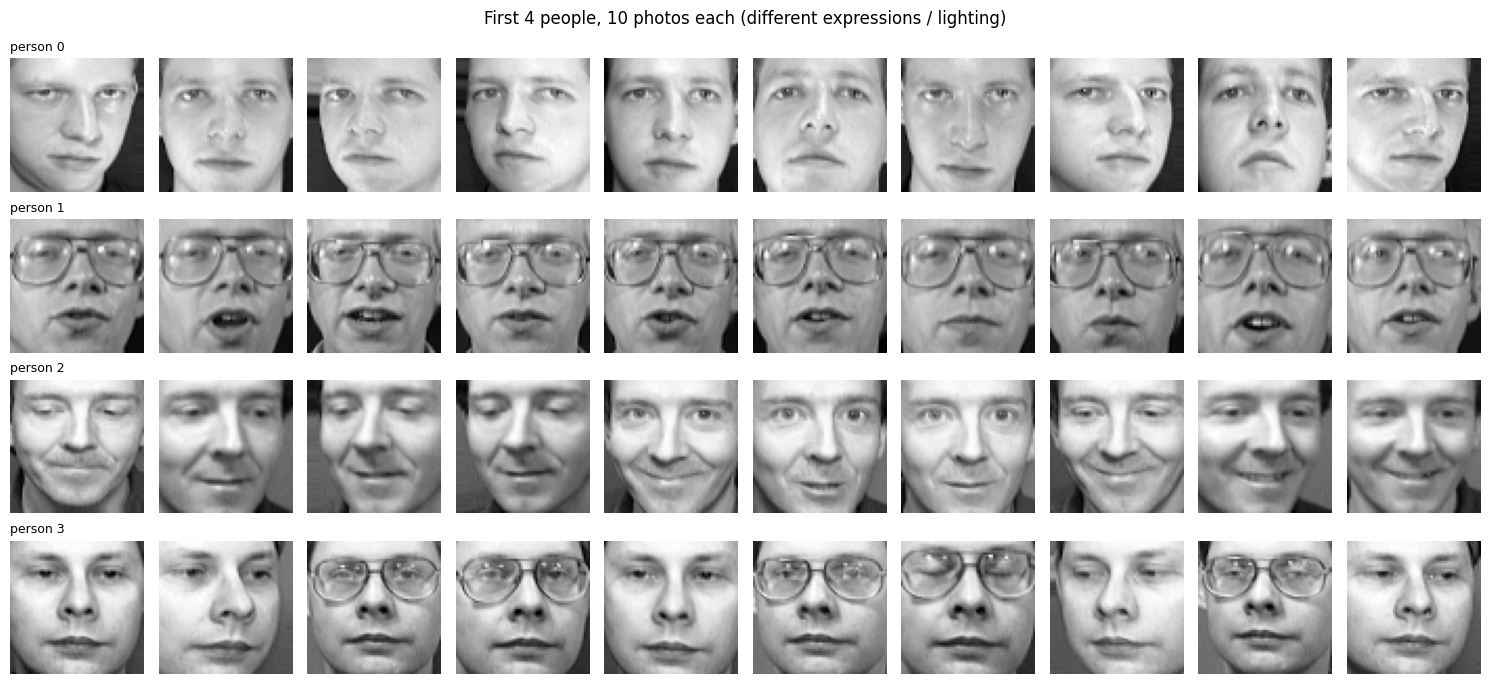

In [3]:
fig, axes = plt.subplots(4, 10, figsize=(15, 7))
for p, row in enumerate(axes):
    idxs = np.where(y == p)[0][:10]
    for ax, i in zip(row, idxs):
        ax.imshow(X[i], cmap="gray"); ax.axis("off")
    row[0].set_title(f"person {p}", fontsize=9, loc="left")
plt.suptitle("First 4 people, 10 photos each (different expressions / lighting)")
plt.tight_layout(); plt.show()

## 3. Train / test split

Stratified, so every person appears in both sets (7 photos for training, 3 for testing).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (280, 64, 64) Test: (120, 64, 64)


## 4. Method 1: Eigenfaces (PCA) + SVM

PCA finds the main directions in which faces differ ("eigenfaces"). Each face becomes a short vector of coefficients, and an SVM classifies those vectors.

In [5]:
n_components = 60
Xtr_flat = X_train.reshape(len(X_train), -1)
Xte_flat = X_test.reshape(len(X_test), -1)

pca = PCA(n_components=n_components, whiten=True, random_state=SEED).fit(Xtr_flat)
Xtr_pca, Xte_pca = pca.transform(Xtr_flat), pca.transform(Xte_flat)

svm = SVC(kernel="rbf", C=10, gamma="scale").fit(Xtr_pca, y_train)
svm_pred = svm.predict(Xte_pca)
svm_acc = accuracy_score(y_test, svm_pred)
print(f"Eigenfaces + SVM test accuracy: {svm_acc:.1%}")

Eigenfaces + SVM test accuracy: 96.7%


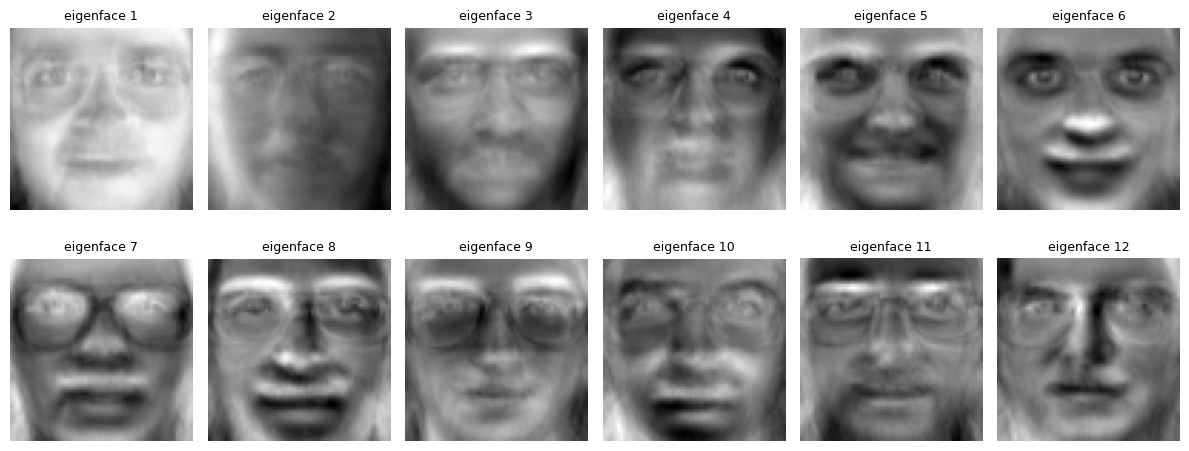

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for ax, comp, k in zip(axes.flat, pca.components_, range(12)):
    ax.imshow(comp.reshape(64, 64), cmap="gray"); ax.set_title(f"eigenface {k+1}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Method 2: Small CNN

In [7]:
Xtr_cnn = X_train[..., np.newaxis]
Xte_cnn = X_test[..., np.newaxis]

# Data augmentation matters here because there are only 7 photos per person
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.08, 0.08),
])

cnn = models.Sequential([
    layers.Input(shape=(64, 64, 1)),
    augment,
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(n_people),
])

cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=["accuracy"])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687,784 (2.62 MB)

 Trainable params: 687,784 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = cnn.fit(
    Xtr_cnn, y_train,
    validation_data=(Xte_cnn, y_test),
    epochs=60, batch_size=32, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=12,
                                                restore_best_weights=True)],
)

Epoch 1/60
9/9 - 4s - 422ms/step - accuracy: 0.0179 - loss: 3.7132 - val_accuracy: 0.0250 - val_loss: 3.6880
Epoch 2/60
9/9 - 1s - 64ms/step - accuracy: 0.0250 - loss: 3.6919 - val_accuracy: 0.0250 - val_loss: 3.6884
Epoch 3/60
9/9 - 1s - 56ms/step - accuracy: 0.0107 - loss: 3.6893 - val_accuracy: 0.0250 - val_loss: 3.6882
Epoch 4/60
9/9 - 1s - 62ms/step - accuracy: 0.0321 - loss: 3.6892 - val_accuracy: 0.0250 - val_loss: 3.6883
Epoch 5/60
9/9 - 1s - 57ms/step - accuracy: 0.0286 - loss: 3.6889 - val_accuracy: 0.0250 - val_loss: 3.6882
Epoch 6/60
9/9 - 1s - 58ms/step - accuracy: 0.0286 - loss: 3.6898 - val_accuracy: 0.0417 - val_loss: 3.6884
Epoch 7/60
9/9 - 1s - 58ms/step - accuracy: 0.0536 - loss: 3.6886 - val_accuracy: 0.0417 - val_loss: 3.6882
Epoch 8/60
9/9 - 1s - 58ms/step - accuracy: 0.0179 - loss: 3.6892 - val_accuracy: 0.0417 - val_loss: 3.6881
Epoch 9/60
9/9 - 1s - 57ms/step - accuracy: 0.0214 - loss: 3.6887 - val_accuracy: 0.0250 - val_loss: 3.6876
Epoch 10/60
9/9 - 1s - 58ms

CNN test accuracy: 84.2%


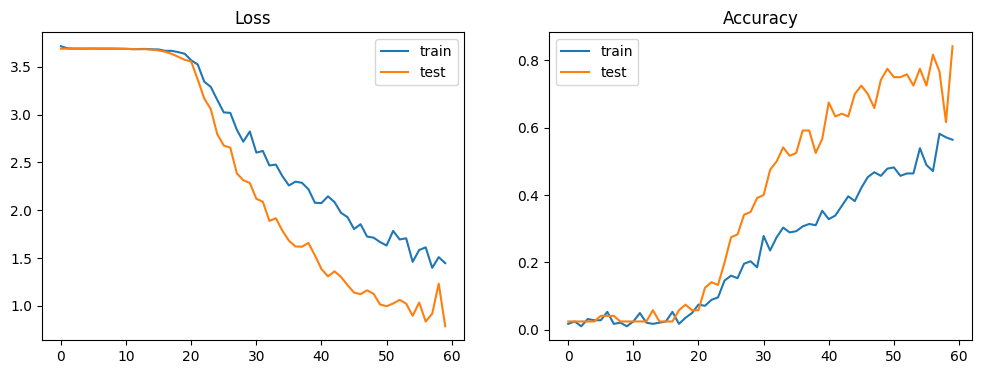

In [9]:
cnn_loss, cnn_acc = cnn.evaluate(Xte_cnn, y_test, verbose=0)
print(f"CNN test accuracy: {cnn_acc:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train"); axes[0].plot(history.history["val_loss"], label="test")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train"); axes[1].plot(history.history["val_accuracy"], label="test")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

## 6. Compare and inspect predictions

Eigenfaces + SVM : 96.7%
Small CNN        : 84.2%


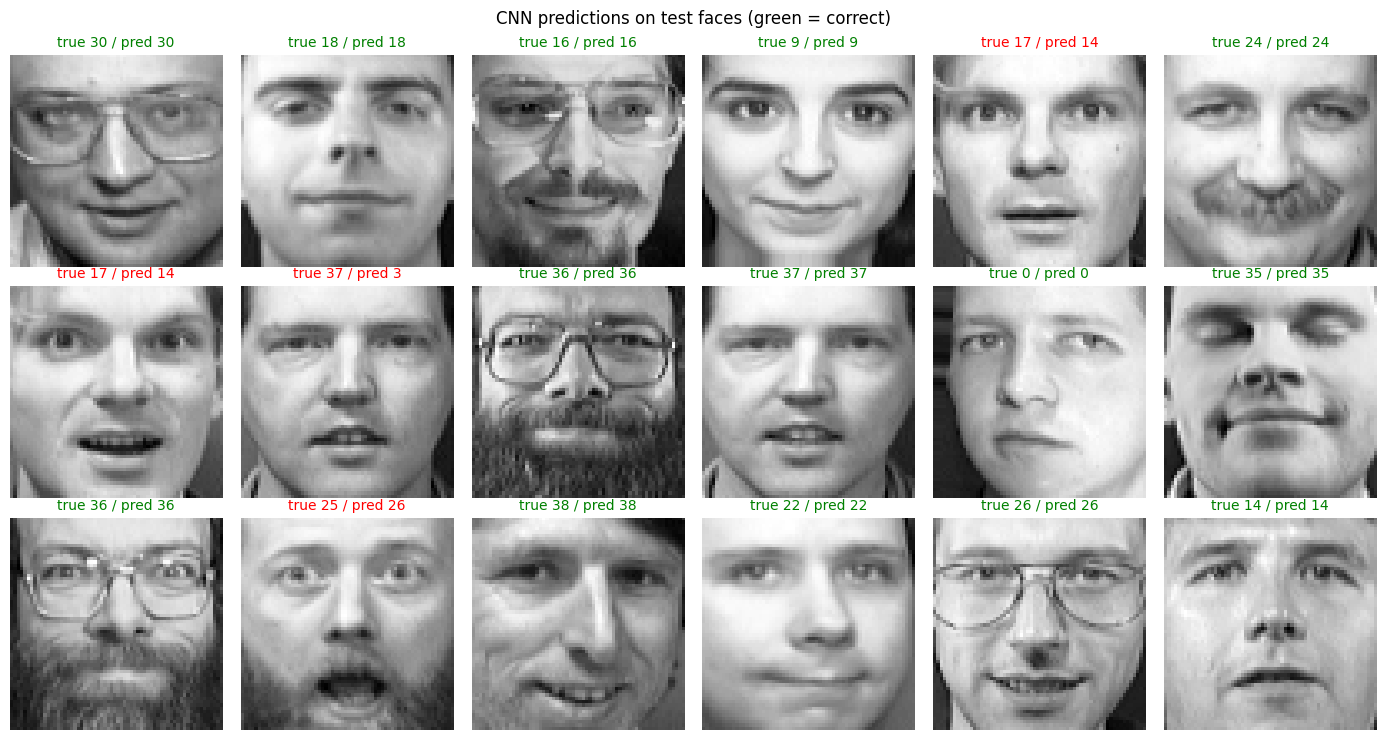

In [10]:
print(f"Eigenfaces + SVM : {svm_acc:.1%}")
print(f"Small CNN        : {cnn_acc:.1%}")

cnn_pred = np.argmax(cnn.predict(Xte_cnn, verbose=0), axis=1)

fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for ax, i in zip(axes.flat, range(18)):
    ax.imshow(X_test[i], cmap="gray"); ax.axis("off")
    ok = cnn_pred[i] == y_test[i]
    ax.set_title(f"true {y_test[i]} / pred {cnn_pred[i]}", color="green" if ok else "red", fontsize=10)
plt.suptitle("CNN predictions on test faces (green = correct)")
plt.tight_layout(); plt.show()

CNN mistakes: 19 of 120


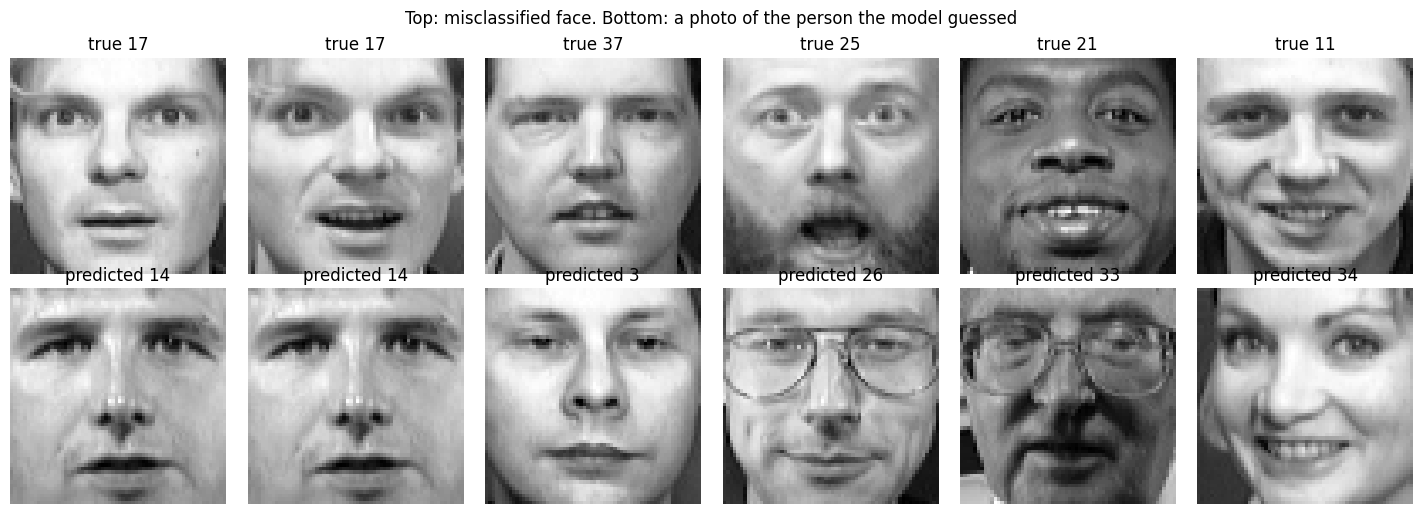

In [11]:
errors = np.where(cnn_pred != y_test)[0]
print(f"CNN mistakes: {len(errors)} of {len(y_test)}")
if len(errors):
    show = errors[:6]
    fig, axes = plt.subplots(2, len(show), figsize=(2.4 * len(show), 5.2), squeeze=False)
    for col, i in enumerate(show):
        axes[0, col].imshow(X_test[i], cmap="gray"); axes[0, col].set_title(f"true {y_test[i]}"); axes[0, col].axis("off")
        match = X_train[np.where(y_train == cnn_pred[i])[0][0]]
        axes[1, col].imshow(match, cmap="gray"); axes[1, col].set_title(f"predicted {cnn_pred[i]}"); axes[1, col].axis("off")
    plt.suptitle("Top: misclassified face. Bottom: a photo of the person the model guessed")
    plt.tight_layout(); plt.show()

## 7. Recognize one face

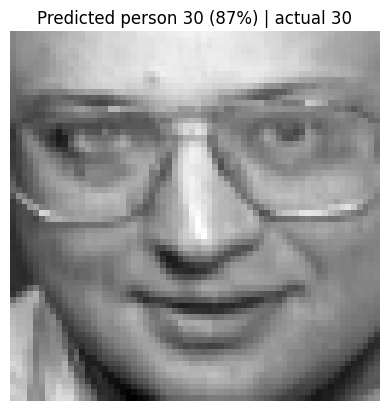

In [12]:
def recognize(img64):
    """img64: a 64x64 grayscale array with values in [0, 1]. Returns (person_id, confidence)."""
    probs = tf.nn.softmax(cnn.predict(img64[np.newaxis, ..., np.newaxis], verbose=0)[0]).numpy()
    return int(np.argmax(probs)), float(probs.max())

sample = X_test[0]
pid, conf = recognize(sample)
plt.imshow(sample, cmap="gray"); plt.axis("off")
plt.title(f"Predicted person {pid} ({conf:.0%}) | actual {y_test[0]}")
plt.show()

## Notes
- Expected accuracy: Eigenfaces + SVM roughly 90-97%, CNN roughly 85-95% (small data, so results vary a little between runs).